# Estado del arte: ajuste de curvas, tasas estocásticas, modelos de depósitos, la recalibración de 2024 y la brecha de código abierto

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 01 a 06 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- ubicar los métodos del caso (curvas de Nelson-Siegel y Svensson, Nelson-Siegel dinámico, escenarios de Hull-White, la cartera replicante, el beta de depósitos, los modelos de prepago) en el estado del arte que encontró la investigación, con sus fuentes, y decir qué implementa el motor y qué no;
- medir cuánto mueve el EVE de un mismo balance la elección de la familia de curvas;
- comparar las aproximaciones de primer orden por brecha y por duración con la revaluación completa y con el NII dinámico en las mismas tres fechas, y decir cuándo discrepan incluso en el signo;
- comparar tres tratamientos de los depósitos (todo depósito a un día, los topes del estándar y la cartera replicante interna) sobre los mismos flujos;
- leer lado a lado las calibraciones de 2016 y de 2024, y declarar lo que se sabe de las herramientas de código abierto que podrían desafiar los resultados;
- comparar cada recálculo con el valor versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, en tres fechas de valoración, 2021-Q4, 2022-Q2 y 2022-Q4, tal como Contraste lo versiona: los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**. El dinero está en miles de USD y un delta EVE positivo es una pérdida.

- **Archivos que se leen:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`, `behavioural_comparison`, `ladder`, `dynamic_nii`, `nmd_segments`) y `models-svb-2021-2022.json` (`fit.nmd_models`, los ajustes replicantes). Las notas de investigación detrás del estado del arte son los dossiers 01 (marco de Basilea), 03 (Chile) y 05 (modelos de mercado, ALM y liquidez) de la investigación de Contraste.

El cuaderno de nivel 3 compara, sobre los mismos datos, lo que hace el caso (niveles 1 y 2) con lo que ofrece la literatura. La celda siguiente carga los archivos y reconstruye, para cada fecha, los flujos netos del balance bajo el tratamiento conductual y el contractual (como en el cuaderno 01).

In [2]:
# Cargar las tres fechas y el documento de modelos; reconstruir los flujos netos de cada tratamiento y las tasas cero en los puntos medios
ROOT = Path("../../..").resolve()
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {"behavioural": "conductual", "contractual": "contractual", "parallel-up": "paralelo al alza",
        "parallel-down": "paralelo a la baja", "steepener": "empinamiento", "flattener": "aplanamiento",
        "short-up": "corto al alza", "short-down": "corto a la baja", True: "sí", False: "no"}

book = {}
for q, d in docs.items():
    o = d["outputs"]
    sides = {}
    for treatment in ("behavioural", "contractual"):
        a, l = np.zeros(19), np.zeros(19)
        for item in o["balance_sheet"]["items"]:
            for row in item["cash_flows"][treatment]:
                if item["side"] == "asset":
                    a[row["bucket"] - 1] += row["amount"]
                else:
                    l[row["bucket"] - 1] -= row["amount"]
        sides[treatment] = (a, l)
    book[q] = {"flows": sides, "r0": np.array(o["curve"]["zero_rates_at_midpoints"]), "tier1": o["scenarios"][0]["outlier"]["tier1"]}
    print(q, o["valuation_date"], "| calculado por riskvalidation", d["provenance"]["riskvalidation_version"], "| instalado", rv.__version__, "| Tier 1", f"{book[q]['tier1']:,.0f}")

2021-Q4 2021-12-31 | calculado por riskvalidation 0.9.0 | instalado 0.9.0 | Tier 1 14,622,000
2022-Q2 2022-06-30 | calculado por riskvalidation 0.9.0 | instalado 0.9.0 | Tier 1 16,349,000
2022-Q4 2022-12-31 | calculado por riskvalidation 0.9.0 | instalado 0.9.0 | Tier 1 16,995,000


## Método

Cada comparación siguiente usa los mismos flujos y curvas versionados que los cuadernos de nivel 2 y cambia una elección a la vez, de modo que una diferencia en el resultado se pueda atribuir a esa elección. Hay cuatro comparaciones: (1) la familia de curvas, (2) las aproximaciones de primer orden contra la revaluación completa y la proyección dinámica, (3) tres tratamientos de los depósitos, y (4) las calibraciones de 2016 y de 2024. Las tres primeras corren el motor sobre los datos versionados; la cuarta lee los escenarios versionados. Cada una se presenta con el estado del arte que representa, en la sección siguiente.

## Estado del arte

La investigación (dossier 05, D.1 a D.7, y dossier 01, H) encontró las siguientes familias para cada parte de la medición de IRRBB. La columna derecha dice qué implementa el motor `riskvalidation` 0.8.1 y qué no, según su código en la etiqueta.

| Parte | Estado del arte (fuente) | En el motor |
|---|---|---|
| Ajuste de curvas | Nelson y Siegel (1987, https://doi.org/10.1086/296409); Svensson (1994, https://doi.org/10.3386/w4871); Nelson-Siegel dinámico, Diebold y Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) | `fit_nelson_siegel`, `fit_svensson`, `fit_dns_factors`, `forecast_dns_factors`; el decaimiento 0,0609 por mes es una constante |
| Interpolación | Hagan y West (2006, https://doi.org/10.1080/13504860500396032): la convexa monótona y otros esquemas cambian los plazos de forma material | lineal en el plazo, plana fuera de la grilla (`zero_rates_at`); ningún otro esquema |
| Escenarios de tasa corta | Vasicek (1977, https://doi.org/10.1016/0304-405X(77)90016-2); Hull y White (1990, https://doi.org/10.1093/rfs/3.4.573) | `hw1f_scenarios` (Hull-White de un factor, antitético); sin Vasicek |
| Depósitos a la vista | cartera replicante estática (BCBS d368, nota 38); valoración por derechos contingentes, Jarrow y van Deventer (1998, https://doi.org/10.1016/S0378-4266(97)00058-7); modelo de tres factores, Kalkbrener y Willing (2004, https://doi.org/10.1016/S0378-4266(03)00131-6); programación estocástica, Frauendorfer y Schurle (2003, https://doi.org/10.1016/S0377-2217(02)00626-4) | `replicating_portfolio` (estática, exacta hasta 10 tramos); ninguno de los otros tres |
| Beta de depósitos | traspaso asimétrico, Drechsler, Savov y Schnabl (2021, https://doi.org/10.1111/jofi.13013) | `deposit_beta_passthrough` (betas al alza y a la baja); el ajuste es del pipeline |
| Prepago | SMM, CPR y PSA, Fuster, Lucca y Vickery (2022); ejercicio racional, Stanton (1995, https://doi.org/10.1093/rfs/8.3.677); riesgos proporcionales, Schwartz y Torous (1989, https://doi.org/10.1111/j.1540-6261.1989.tb05062.x); riesgos competitivos, Deng, Quigley y Van Order (2000, https://doi.org/10.1111/1468-0262.00110) | `smm_from_cpr`, `cpr_from_smm`, `psa_cpr`, `prepayment_logit` y `fit_prepayment_logit` (un logit sobre incentivo y antigüedad; sin agotamiento ni estacionalidad) |
| Tamaños de choque | BCBS d368 (2016) y la recalibración d578 (2024, vigente desde 2026-01-01): percentil 99,9 de cambios de seis meses, 2000 a 2023, redondeado a 25 pb | ambas tablas como fixtures (`shock_table`); la de 2016 está verificada con una salvedad de la capa de texto, la de 2024 es la Tabla 2 de SRP31.90 |
| La lección del banco quebrado | la revisión de la Reserva Federal encontró que el banco hizo supuestos contraintuitivos sobre la duración de los depósitos para enfrentar un exceso (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf) | `eve_with_without_behavioural` y `behavioural_change_at_breach` (cuadernos 05 y 08) |
| Motores de código abierto | la investigación no encontró un motor ALM o IRRBB de código abierto maduro; ORE y QuantLib cubren curvas, Hull-White y exposición, no el balance de un banco (dossier 05, D.6 e I.3) | no aplica; la ausencia es un hallazgo de la búsqueda del dossier, **NO VERIFICADA** más allá de ella |

Dos cautelas sobre la tabla. La investigación anota que los valores de 2024 no se obtuvieron en el dossier de mercado (dossier 05, D.2: "NO VERIFICADO") y están transcritos en el dossier de Basilea (dossier 01, H.3); el motor toma el segundo. Y el decaimiento de Diebold-Li se declara en el artículo como el que maximiza la carga de curvatura a los 30 meses; el motor documenta 29,446 meses (cuaderno 04).

### Comparación 1: la familia de curvas

Hagan y West (2006) muestran que el esquema de interpolación mueve de forma material las tasas a plazo; la familia ajustada a la curva de mercado hace lo mismo con los valores presentes. La celda compara cuatro maneras de obtener las 19 tasas cero de cada fecha desde los mismos 12 rendimientos observados: la del pipeline (bootstrap e interpolación lineal), el ajuste Nelson-Siegel, el ajuste Svensson y las cargas del Nelson-Siegel dinámico con el decaimiento fijo. Para cada una la celda recalcula el EVE de los flujos netos conductuales e imprime la diferencia contra la del pipeline, en dinero y como proporción del Tier 1, y la mayor brecha en las tasas.

In [3]:
# EVE de los flujos conductuales con cuatro maneras de obtener las tasas cero, contra la curva interpolada del pipeline
families = {}
print(f"{'':8s} {'curva':26s} {'EVE':>14s} {'diferencia':>14s} {'del Tier 1':>12s} {'mayor brecha de tasa (pb)':>28s}")
for q, d in docs.items():
    pts = d["outputs"]["curve"]["points"]
    tenors = np.array([p["tenor_years"] for p in pts])
    zero = np.array([p["zero_rate"] for p in pts])
    ns = curves.fit_nelson_siegel(tenors, zero)
    sv = curves.fit_svensson(tenors, zero)
    factors = curves.fit_dns_factors(tenors * 12.0, zero[None, :])[0]
    rates = {
        "pipeline: bootstrap + lineal": book[q]["r0"],
        "Nelson-Siegel": curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau),
        "Svensson": curves.svensson_yield(MID, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2),
        "Nelson-Siegel dinámico (λ fijo)": curves.dns_yield(MID * 12.0, *factors),
    }
    a, l = book[q]["flows"]["behavioural"]
    reference = None
    for name, r in rates.items():
        value = eve_nii.eve(a - l, r, MID)
        reference = value if reference is None else reference
        families[(q, name)] = value
        print(f"{q:8s} {name:26s} {value:14,.0f} {value - reference:14,.0f} {(value - reference) / book[q]['tier1']:12.4f} {np.abs(r - book[q]['r0']).max() * 1e4:28.1f}")

         curva                                 EVE     diferencia   del Tier 1    mayor brecha de tasa (pb)
2021-Q4  pipeline: bootstrap + lineal      8,982,670              0       0.0000                          0.0
2021-Q4  Nelson-Siegel                   8,813,494       -169,176      -0.0116                         10.2
2021-Q4  Svensson                        8,961,548        -21,122      -0.0014                         24.0
2021-Q4  Nelson-Siegel dinámico (λ fijo)      8,841,860       -140,810      -0.0096                         11.7
2022-Q2  pipeline: bootstrap + lineal      7,036,780              0       0.0000                          0.0
2022-Q2  Nelson-Siegel                   7,142,430        105,650       0.0065                         46.3
2022-Q2  Svensson                        6,647,794       -388,987      -0.0238                         31.0
2022-Q2  Nelson-Siegel dinámico (λ fijo)      7,360,948        324,168       0.0198                         37.4
2022-Q4  pipel

### Comparación 2: las aproximaciones de primer orden, la revaluación completa y el NII dinámico

El cuaderno 01 dio dos aproximaciones de primer orden, la brecha de reprecio para el NII y la brecha de duración para el patrimonio. Son baratas, no necesitan curva de escenario, y la literatura las trata como indicadores; el estándar pide la revaluación completa. La celda las pone lado a lado para un choque paralelo de +200 pb, el tamaño del USD de la tabla de 2024, en las tres fechas y los dos tratamientos de los depósitos. Para el patrimonio, el cambio de primer orden es $-DGAP \cdot A \cdot \Delta y$ (escalado desde los +100 pb que devuelve el motor, pues es lineal en el desplazamiento), y la revaluación completa es el delta EVE versionado del choque paralelo al alza, con la pérdida positiva. Para el NII, la aproximación por brechas es el doble del valor del motor a +100 pb, y la proyección dinámica es la versionada, con la pérdida positiva (un número negativo es una ganancia).

In [4]:
# Pérdida por la brecha de duración y por la revaluación completa, y pérdida de NII por la brecha y por la proyección dinámica, para +200 pb
print(f"{'':8s} {'depósitos':14s} {'patrimonio: primer orden':>26s} {'patrimonio: revaluación':>28s} {'NII: brecha':>14s} {'NII: dinámico':>16s}")
approx = {}
for q, d in docs.items():
    o = d["outputs"]
    dynamic_up = next(s["delta_vs_base"] for s in o["dynamic_nii"]["scenarios"] if s["scenario"] == "parallel-up")
    for treatment in ("behavioural", "contractual"):
        a, l = book[q]["flows"][treatment]
        dg = eve_nii.duration_gap(a, l, book[q]["r0"], MID)
        first_order_loss = -2.0 * dg.equity_change_100bp_up
        full = next(r for r in o["behavioural_comparison"] if r["calibration"] == "2024" and r["shock"] == "parallel-up")[f"delta_eve_{treatment}"]
        gap_nii = 2.0 * eve_nii.delta_nii_gap(eve_nii.repricing_gap(a, l), MID, 100.0)
        approx[(q, treatment)] = (first_order_loss, full, gap_nii, dynamic_up)
        shown_dynamic = f"{dynamic_up:16,.0f}" if treatment == "behavioural" else f"{'-':>16s}"
        print(f"{q:8s} {NAME[treatment]:14s} {first_order_loss:26,.0f} {full:28,.0f} {gap_nii:14,.0f} {shown_dynamic}")

         depósitos        patrimonio: primer orden      patrimonio: revaluación    NII: brecha    NII: dinámico
2021-Q4  conductual                      5,549,598                    4,696,830        455,806       -1,138,367
2021-Q4  contractual                    17,508,990                   15,541,007      2,471,558                -
2022-Q2  conductual                      4,016,983                    3,389,351        398,114       -1,058,869
2022-Q2  contractual                    14,096,514                   12,611,380      2,398,976                -
2022-Q4  conductual                      3,602,676                    3,058,469        349,294         -483,444
2022-Q4  contractual                    12,246,721                   10,983,866      2,186,939                -


### Comparación 3: tres tratamientos de los depósitos

El estándar ubica la parte estable de los depósitos a la vista bajo topes; la práctica interna replica el depósito con una cartera de tramos rodantes y usa su plazo promedio. La celda toma el segmento mayorista, el más grande, y lo ubica de tres maneras con `nmd_split` del motor: todo depósito a un día (la lectura contractual), los topes del estándar (la lectura conductual versionada, 50 por ciento estable a 4 años), y la lectura **replicante**, donde todo el saldo está en el plazo promedio del ajuste replicante versionado de la fecha (proporción 100 por ciento, sin tope, `enforce_caps=False`). El resto del balance se mantiene como está versionado. Para cada tratamiento imprime el EVE y la pérdida bajo el choque paralelo de +200 pb con piso en cero, de modo que solo cambia el tratamiento de los depósitos mayoristas. Es un qué pasaría sobre los flujos versionados (omite de los flujos con choque el rescate anticipado de depósitos a plazo, una partida de 322.000), no un número versionado.

In [5]:
# Ubicar los depósitos mayoristas de tres maneras y calcular el EVE y la pérdida bajo +200 pb con piso en cero
deposit = {}
print(f"{'':8s} {'tratamiento':22s} {'plazo promedio (a)':>24s} {'EVE':>14s} {'pérdida +200 pb':>18s} {'del Tier 1':>12s}")
for q, d in docs.items():
    o = d["outputs"]
    segment = next(s for s in o["nmd_segments"] if s["category"] == "wholesale")
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == o["valuation_date"])
    standard = slotting.nmd_split(segment["balance"], "wholesale", segment["requested_core_share"], segment["requested_core_maturity_years"])
    a, l = book[q]["flows"]["behavioural"]
    others = (a - l) + standard.flows
    treatments = {
        "contractual": slotting.nmd_split(segment["balance"], "wholesale", 0.0, 0.0),
        "topes del estándar": standard,
        "cartera replicante": slotting.nmd_split(segment["balance"], "wholesale", 1.0, model["weighted_average_maturity_years"], enforce_caps=False),
    }
    shocked_rates = shocks.apply_floor(book[q]["r0"], np.full(19, 200.0), 0.0)
    for name, split in treatments.items():
        net = others - split.flows
        value = eve_nii.eve(net, book[q]["r0"], MID)
        loss = eve_nii.delta_eve(net, net, book[q]["r0"], shocked_rates, MID)
        wam = float((split.flows * MID).sum() / split.flows.sum())
        deposit[(q, name)] = (value, loss)
        print(f"{q:8s} {NAME.get(name, name):22s} {wam:24.4f} {value:14,.0f} {loss:18,.0f} {loss / book[q]['tier1']:12.4f}")

         tratamiento                  plazo promedio (a)            EVE    pérdida +200 pb   del Tier 1
2021-Q4  contractual                              0.0028      4,868,904         11,542,342       0.7894
2021-Q4  topes del estándar                       2.0014      8,982,670          4,696,651       0.3212
2021-Q4  cartera replicante                       4.7595     15,459,666         -4,423,382      -0.3025
2022-Q2  contractual                              0.0028     -3,373,439          9,694,356       0.5930
2022-Q2  topes del estándar                       2.0014      7,036,780          3,389,057       0.2073
2022-Q2  cartera replicante                       4.2049     18,465,257         -3,460,623      -0.2117
2022-Q4  contractual                              0.0028     -7,338,446          8,571,364       0.5043
2022-Q4  topes del estándar                       2.0014      5,257,968          3,056,308       0.1798
2022-Q4  cartera replicante                       5.0000     22,

### Comparación 4: las calibraciones de 2016 y de 2024

La recalibración de los tamaños de choque (d578, vigente desde 2026-01-01) es el único cambio del estándar en el período. Los escenarios versionados guardan los seis choques bajo ambas tablas con los flujos conductuales con tope, así que el efecto sobre la medida de riesgo EVE es una lectura. La celda imprime, para cada fecha, la medida, el peor choque y la razón al Tier 1 bajo cada calibración.

In [6]:
# La medida de riesgo EVE, el peor choque y la razón al Tier 1 bajo las calibraciones de 2016 y de 2024 (flujos conductuales)
print(f"{'':8s} {'calibración':14s} {'paralelo, corto, largo (pb)':>32s} {'medida':>12s} {'peor choque':>22s} {'razón':>8s}")
for q, d in docs.items():
    for cal in ("2016", "2024"):
        b = next(s for s in d["outputs"]["scenarios"] if s["calibration"] == cal and s["nmd_assumption"] == "behavioural")
        z = b["shock_size"]
        print(f"{q:8s} {cal:14s} {z['parallel_bp']:.0f}/{z['short_bp']:.0f}/{z['long_bp']:.0f}{'':>20s} {b['eve_risk_measure']:12,.0f} {NAME[b['worst_shock']]:>22s} {b['outlier']['ratio']:8.4f}")

         calibración         paralelo, corto, largo (pb)       medida            peor choque    razón
2021-Q4  2016           200/300/150                        4,696,830       paralelo al alza   0.3212
2021-Q4  2024           200/300/225                        4,980,555           empinamiento   0.3406
2022-Q2  2016           200/300/150                        3,389,351       paralelo al alza   0.2073
2022-Q2  2024           200/300/225                        3,418,185           empinamiento   0.2091
2022-Q4  2016           200/300/150                        3,058,469       paralelo al alza   0.1800
2022-Q4  2024           200/300/225                        3,072,781           empinamiento   0.1808


La última celda dibuja el EVE bajo las cuatro familias de curvas en las tres fechas (izquierda) y la pérdida bajo +200 pb para los tres tratamientos de los depósitos mayoristas (derecha). A la izquierda las cuatro familias están cerca: las diferencias son una proporción pequeña del Tier 1. A la derecha la elección del tratamiento mueve la pérdida en un múltiplo.

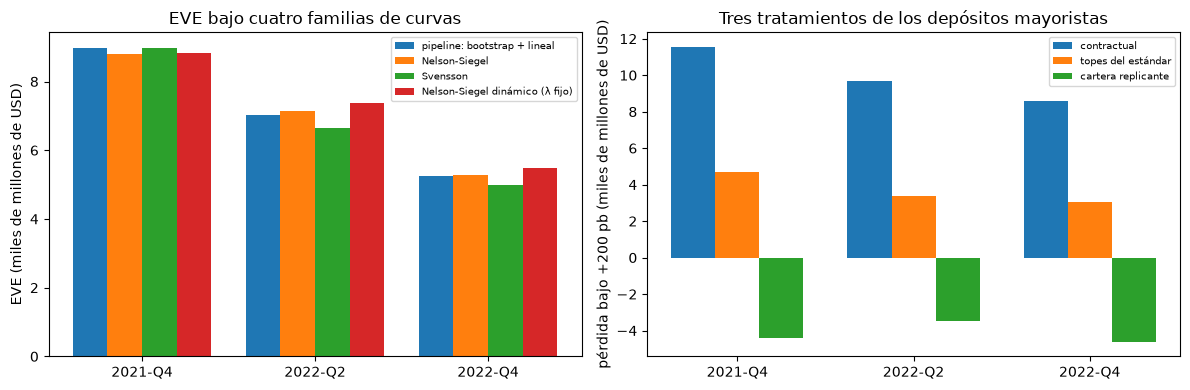

In [7]:
# Dibujar el EVE bajo cuatro familias de curvas y la pérdida bajo +200 pb para los tres tratamientos de depósitos
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
names = list(dict.fromkeys(n for _, n in families))
for k, name in enumerate(names):
    left.bar(np.arange(3) + k * 0.2 - 0.3, [families[(q, name)] / 1e6 for q in docs], 0.2, label=name)
left.set_xticks(range(3))
left.set_xticklabels(list(docs))
left.set_ylabel("EVE (miles de millones de USD)")
left.set_title("EVE bajo cuatro familias de curvas")
left.legend(fontsize=7)
treat = list(dict.fromkeys(n for _, n in deposit))
for k, name in enumerate(treat):
    right.bar(np.arange(3) + k * 0.25 - 0.25, [deposit[(q, name)][1] / 1e6 for q in docs], 0.25, label=NAME.get(name, name))
right.set_xticks(range(3))
right.set_xticklabels(list(docs))
right.set_ylabel("pérdida bajo +200 pb (miles de millones de USD)")
right.set_title("Tres tratamientos de los depósitos mayoristas")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Resultados

- **Lo que cubre el motor.** De las familias que encontró la investigación, el motor implementa los ajustes de curva, Hull-White de un factor, la cartera replicante estática, el beta de depósitos y un logit de prepago, y no implementa Vasicek, otro esquema de interpolación, los modelos de depósitos por derechos contingentes o de tres factores, ni la programación estocástica. Un validador que los necesite tiene que traer un contraste de fuera; la investigación no encontró un motor ALM de código abierto maduro que traer, un hallazgo que sigue sin verificarse más allá de la búsqueda del dossier.
- **La familia de curvas.** Sobre los mismos 12 rendimientos observados, las cuatro maneras de obtener las 19 tasas cero difieren de la del pipeline hasta en 52 pb en una sola banda y mueven el EVE entre -389.000 y +324.000, como máximo 2,4 por ciento del Tier 1 pero hasta 10 por ciento del propio EVE: al 2022-Q2 los cuatro EVE van de 6.647.794 (Svensson) a 7.360.948 (Nelson-Siegel dinámico) en torno a los 7.036.780 del pipeline. La curva del pipeline pasa por todos los puntos observados y las familias ajustadas los suavizan (al 2022-Q2, con errores de 10 y 13 pb), así que la comparación dice cuán sensible es el resultado a la elección, no cuál curva es la correcta. La medida de Basilea es una razón al Tier 1, así que la elección no cambia aquí un veredicto, pero es una dispersión que un validador debe informar.
- **Las aproximaciones de primer orden.** Para +200 pb la brecha de duración sobrestima la pérdida de la revaluación completa en 18 por ciento con los depósitos conductuales (5.549.598 frente a 4.696.830 al 2021-Q4, 4.016.983 frente a 3.389.351 al 2022-Q2, 3.602.676 frente a 3.058.469 al 2022-Q4) y en 11 a 13 por ciento con los contractuales: el orden de magnitud y el signo correctos, con un sesgo estable entre las fechas. Las aproximaciones del NII no coinciden ni en el signo: la brecha dice que un choque de +200 pb cuesta 455.806, 398.114 y 349.294, y la proyección dinámica dice que gana 1.138.367, 1.058.869 y 483.444. La diferencia es el traspaso de los depósitos (la brecha reprecia los depósitos no estables uno a uno, la proyección les da un beta de 0,02 a 0,26), así que el signo de la sensibilidad del NII de este banco es una afirmación sobre su beta de depósitos.
- **Los depósitos.** Al 2022-Q2 los depósitos mayoristas, 185 mil millones del balance, dan tres bancos distintos. Ubicados a un día, el EVE es -3.373.439 y la pérdida a +200 pb 9.694.356, 59 por ciento del Tier 1. Con los topes del estándar, el EVE es 7.036.780 y la pérdida 3.389.057, 21 por ciento (el número versionado es 3.389.351; los 294 de diferencia son el rescate anticipado de depósitos a plazo que aquí se omite). Con la cartera replicante todo el saldo está a 4,2 años, el EVE es 18.465.257 y el choque de +200 pb es **una ganancia** de 3.460.623. El signo se invierte en las tres fechas (4,76, 4,20 y 5,00 años). Es la palanca que describe la revisión del banco quebrado: una duración larga de los depósitos, ajustada con la historia del propio banco, puede hacer desaparecer una pérdida, y los topes del estándar son lo que lo impide. El cuaderno 05 mostró que los pesos detrás de esos plazos no son estables.
- **La recalibración de 2024.** Bajo los tamaños de 2016 el peor choque es el paralelo al alza en las tres fechas; bajo los de 2024, cuyo tamaño largo es 225 pb en vez de 150 pb, es el empinamiento. La medida sube 6,0 por ciento en 2021-Q4 (4.696.830 a 4.980.555), 0,9 por ciento en 2022-Q2 y 0,5 por ciento en 2022-Q4, y la razón queda sobre la línea de 15 por ciento en todos los casos: la recalibración cambia la forma que más daña, no el veredicto de este caso.
- **Lo que el cuaderno no muestra.** Que alguna de las alternativas sea mejor que las elecciones del pipeline: no hay una verdad contra la cual comparar para un banco cuyo comportamiento es sintético. El cuaderno muestra el tamaño de las elecciones, para que un validador sepa dónde mirar primero: el tratamiento de los depósitos, luego el beta, luego la curva.

## Resumen

- El motor implementa una parte del estado del arte: las familias de curvas, Hull-White de un factor, la cartera replicante estática, el beta de depósitos y un logit de prepago; no implementa Vasicek, otros esquemas de interpolación, los modelos de depósitos por derechos contingentes ni de tres factores, ni la programación estocástica.
- La familia de curvas mueve el EVE de los mismos flujos en una proporción pequeña del Tier 1; el tratamiento de los depósitos mueve la pérdida en un múltiplo.
- Las aproximaciones de primer orden dan el orden de magnitud del cambio del patrimonio, pero la brecha y el NII dinámico pueden discrepar incluso en el signo, porque tratan de forma distinta el traspaso de los depósitos.
- La recalibración de 2024 cambia los tamaños del extremo largo y con ello el peor choque del caso, del paralelo al alza al empinamiento, sin cambiar el veredicto de la prueba de valores atípicos.
- No se encontró un motor de código abierto maduro que desafíe los resultados; es un hallazgo de la búsqueda del dossier, no verificado más allá de ella.

**Qué probar a continuación.** Reemplaza los +200 pb de la comparación 3 por el empinamiento del cuaderno 02 y mira si se mantiene el orden de los tres tratamientos de depósitos. Después sigue con el cuaderno 08, los componentes más allá del estado del arte.

## Referencias

- Nelson, C. R. y Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. y Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hagan, P. S. y West, G. (2006), Interpolation methods for curve construction, Applied Mathematical Finance 13(2). https://doi.org/10.1080/13504860500396032
- Vasicek, O. (1977), An equilibrium characterization of the term structure, Journal of Financial Economics 5(2). https://doi.org/10.1016/0304-405X(77)90016-2
- Hull, J. y White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Jarrow, R. y van Deventer, D. (1998), The arbitrage-free valuation and hedging of demand deposits and credit card loans, Journal of Banking and Finance 22(3). https://doi.org/10.1016/S0378-4266(97)00058-7
- Kalkbrener, M. y Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Frauendorfer, K. y Schurle, M. (2003), Multistage stochastic programming: optimal reinvestment of non-maturing liabilities, European Journal of Operational Research 151(3). https://doi.org/10.1016/S0377-2217(02)00626-4
- Drechsler, I., Savov, A. y Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Stanton, R. (1995), Rational prepayment and the valuation of mortgage-backed securities, Review of Financial Studies 8(3). https://doi.org/10.1093/rfs/8.3.677
- Schwartz, E. S. y Torous, W. N. (1989), Prepayment and the valuation of mortgage-backed securities, Journal of Finance 44(2). https://doi.org/10.1111/j.1540-6261.1989.tb05062.x
- Deng, Y., Quigley, J. M. y Van Order, R. (2000), Mortgage terminations, heterogeneity and the exercise of mortgage options, Econometrica 68(2). https://doi.org/10.1111/1468-0262.00110
- Fuster, A., Lucca, D. y Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Dossiers 01, 03 y 05 de la investigación de Contraste (marco de Basilea; Chile; modelos de mercado, ALM y liquidez).